# Project Tittle:

 # 🛒 Blinkit Sales Analysis (2022–2023)


**Project Overview**
  
* This project presents a comprehensive analysis of Blinkit Orders data to understand customer ordering patterns, payment preferences, and overall
business performance. The dataset is cleaned, processed, and analyzed using Python and data visualization libraries to identify meaningful trends in 
order volume, revenue, payment methods, delivery status, and time-based ordering behavior. The analysis highlights peak ordering hours, weekdays,
monthly trends, and customer payment preferences, providing valuable insights that support data-driven decision-making, 
improve operational efficiency, and enhance customer satisfaction.
    
**Research Questions**
* What is the total revenue generated from all Blinkit orders?
* Which payment method is used most frequently by customers?
* On which weekday are the maximum orders placed?
* During which hour of the day are the highest number of orders received?
* Which month records the highest number of orders?
* What is the distribution of different delivery statuses?
    
**Dataset Overview**
* 🛒 Industry: Online Grocery Delivery & E-commerce
* 📦 Data Includes: Customer orders, payment methods, order values, and delivery status.
* 🏪 Stores: Multiple Blinkit store locations identified by Store ID.
* 📅 Time Period: Order data containing daily, monthly, hourly, and weekday transactions.
* 💳 Payment Methods: Card, Cash, UPI, and Wallet.
* 🚚 Delivery Status: Information about the status of each order (e.g., Delivered, Cancelled, Pending, etc.).
* 📊 Key Metrics: Order ID, Store ID, Order Date, Order Total, Payment Method, Delivery Status, Hour, Month, and Weekday.
    
**Project Qbjective**
* Analyze the overall order performance of Blinkit.
* Understand customer ordering behavior and purchasing patterns.
* Identify order trends based on hour, weekday, and month.
* Clean and preprocess the dataset for accurate analysis.
* Analyze the distribution of different payment methods.
* Evaluate order revenue using order total.
* Examine delivery performance through delivery status.
* Visualize order data using interactive charts and graphs.
* Generate meaningful business insights from customer orders.
* Support data-driven decision-making to improve operational efficiency and customer satisfaction.

# Import Requried Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.io as pio
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# Display Library Versions

In [2]:
print("pandas version:",pd.__version__)
print("Numpy version:",np.__version__)
print("Matplotlib version:",matplotlib.__version__)
print("Seaborn Version:",sns.__version__)

pandas version: 3.0.3
Numpy version: 2.5.1
Matplotlib version: 3.11.0
Seaborn Version: 0.13.2


# Loading dataset

In [3]:
df=pd.read_csv("blinkit_orders.csv")
df

,order_id,customer_id,order_date,promised_delivery_time,actual_delivery_time,delivery_status,order_total,payment_method,delivery_partner_id,store_id
0,1961864118,30065862,2024-07-17 08:34:01,2024-07-17 08:52:01,2024-07-17 08:47:01,On Time,3197.07,Cash,63230,4771
1,1549769649,9573071,2024-05-28 13:14:29,2024-05-28 13:25:29,2024-05-28 13:27:29,On Time,976.55,Cash,14983,7534
2,9185164487,45477575,2024-09-23 13:07:12,2024-09-23 13:25:12,2024-09-23 13:29:12,On Time,839.05,UPI,39859,9886
3,9644738826,88067569,2023-11-24 16:16:56,2023-11-24 16:34:56,2023-11-24 16:33:56,On Time,440.23,Card,61497,7917
4,5427684290,83298567,2023-11-20 05:00:39,2023-11-20 05:17:39,2023-11-20 05:18:39,On Time,2526.68,Cash,84315,2741
...,...,...,...,...,...,...,...,...,...,...
4995,1669690997,62600289,2023-12-25 15:46:20,2023-12-25 16:05:20,2023-12-25 16:10:20,On Time,1132.33,Cash,90914,1587
4996,8340761903,53640286,2023-11-27 09:18:43,2023-11-27 09:38:43,2023-11-27 09:36:43,On Time,2372.01,Cash,27952,3458
4997,5936301790,87059497,2024-06-21 19:09:09,2024-06-21 19:23:09,2024-06-21 19:26:09,On Time,3158.35,Cash,9590,7424
4998,5710579377,67310893,2024-06-06 14:58:13,2024-06-06 15:12:13,2024-06-06 15:10:13,On Time,1918.92,UPI,29940,6128


# Data exploration

**Basic Dataset information**

In [4]:
df.shape

(5000, 10)

**Dataset information**

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 10 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   order_id                5000 non-null   int64  
 1   customer_id             5000 non-null   int64  
 2   order_date              5000 non-null   str    
 3   promised_delivery_time  5000 non-null   str    
 4   actual_delivery_time    5000 non-null   str    
 5   delivery_status         5000 non-null   str    
 6   order_total             5000 non-null   float64
 7   payment_method          5000 non-null   str    
 8   delivery_partner_id     5000 non-null   int64  
 9   store_id                5000 non-null   int64  
dtypes: float64(1), int64(4), str(5)
memory usage: 739.9 KB


**Statatics Analysis**

In [6]:
df.describe()

,order_id,customer_id,order_total,delivery_partner_id,store_id
count,5.000000e+03,5.000000e+03,5000.00000,5000.000000,5000.000000
mean,5.029129e+09,5.009685e+07,2201.86170,50050.318200,4999.689000
std,2.863533e+09,2.919082e+07,1303.02438,28802.276922,2886.089242
min,6.046500e+04,3.181300e+04,13.25000,43.000000,1.000000
25%,2.531421e+09,2.404314e+07,1086.21500,24928.500000,2509.250000
50%,5.074378e+09,4.997808e+07,2100.69000,50262.500000,4987.000000
75%,7.488579e+09,7.621215e+07,3156.88250,74478.250000,7500.750000
max,9.998298e+09,9.989390e+07,6721.46000,99968.000000,9995.000000


* Unique values per column

In [7]:
for col in df.columns:
    display(pd.DataFrame({col: df[col].unique()}))

,order_id
0,1961864118
1,1549769649
2,9185164487
3,9644738826
4,5427684290
...,...
4995,1669690997
4996,8340761903
4997,5936301790
4998,5710579377


,customer_id
0,30065862
1,9573071
2,45477575
3,88067569
4,83298567
...,...
2167,10745302
2168,71767248
2169,16484167
2170,86483673


,order_date
0,2024-07-17 08:34:01
1,2024-05-28 13:14:29
2,2024-09-23 13:07:12
3,2023-11-24 16:16:56
4,2023-11-20 05:00:39
...,...
4995,2023-12-25 15:46:20
4996,2023-11-27 09:18:43
4997,2024-06-21 19:09:09
4998,2024-06-06 14:58:13


,promised_delivery_time
0,2024-07-17 08:52:01
1,2024-05-28 13:25:29
2,2024-09-23 13:25:12
3,2023-11-24 16:34:56
4,2023-11-20 05:17:39
...,...
4994,2023-12-25 16:05:20
4995,2023-11-27 09:38:43
4996,2024-06-21 19:23:09
4997,2024-06-06 15:12:13


,actual_delivery_time
0,2024-07-17 08:47:01
1,2024-05-28 13:27:29
2,2024-09-23 13:29:12
3,2023-11-24 16:33:56
4,2023-11-20 05:18:39
...,...
4995,2023-12-25 16:10:20
4996,2023-11-27 09:36:43
4997,2024-06-21 19:26:09
4998,2024-06-06 15:10:13


,delivery_status
0,On Time
1,Slightly Delayed
2,Significantly Delayed


,order_total
0,3197.07
1,976.55
2,839.05
3,440.23
4,2526.68
...,...
4545,1132.33
4546,2372.01
4547,3158.35
4548,1918.92


,payment_method
0,Cash
1,UPI
2,Card
3,Wallet


,delivery_partner_id
0,63230
1,14983
2,39859
3,61497
4,84315
...,...
4995,90914
4996,27952
4997,9590
4998,29940


,store_id
0,4771
1,7534
2,9886
3,7917
4,2741
...,...
4995,1587
4996,3458
4997,7424
4998,6128


* Memory usage

In [8]:
df.memory_usage()

Index                        132
order_id                   40000
customer_id                40000
order_date                135000
promised_delivery_time    135000
actual_delivery_time      135000
delivery_status            91235
order_total                40000
payment_method             61274
delivery_partner_id        40000
store_id                   40000
dtype: int64

**Display the first five rows**

In [9]:
df.head()

,order_id,customer_id,order_date,promised_delivery_time,actual_delivery_time,delivery_status,order_total,payment_method,delivery_partner_id,store_id
0,1961864118,30065862,2024-07-17 08:34:01,2024-07-17 08:52:01,2024-07-17 08:47:01,On Time,3197.07,Cash,63230,4771
1,1549769649,9573071,2024-05-28 13:14:29,2024-05-28 13:25:29,2024-05-28 13:27:29,On Time,976.55,Cash,14983,7534
2,9185164487,45477575,2024-09-23 13:07:12,2024-09-23 13:25:12,2024-09-23 13:29:12,On Time,839.05,UPI,39859,9886
3,9644738826,88067569,2023-11-24 16:16:56,2023-11-24 16:34:56,2023-11-24 16:33:56,On Time,440.23,Card,61497,7917
4,5427684290,83298567,2023-11-20 05:00:39,2023-11-20 05:17:39,2023-11-20 05:18:39,On Time,2526.68,Cash,84315,2741


In [10]:
df.tail()

,order_id,customer_id,order_date,promised_delivery_time,actual_delivery_time,delivery_status,order_total,payment_method,delivery_partner_id,store_id
4995,1669690997,62600289,2023-12-25 15:46:20,2023-12-25 16:05:20,2023-12-25 16:10:20,On Time,1132.33,Cash,90914,1587
4996,8340761903,53640286,2023-11-27 09:18:43,2023-11-27 09:38:43,2023-11-27 09:36:43,On Time,2372.01,Cash,27952,3458
4997,5936301790,87059497,2024-06-21 19:09:09,2024-06-21 19:23:09,2024-06-21 19:26:09,On Time,3158.35,Cash,9590,7424
4998,5710579377,67310893,2024-06-06 14:58:13,2024-06-06 15:12:13,2024-06-06 15:10:13,On Time,1918.92,UPI,29940,6128
4999,2494813730,28663279,2023-08-23 12:04:18,2023-08-23 12:20:18,2023-08-23 12:21:18,On Time,1879.46,Card,32851,5588


In [11]:
df.columns

Index(['order_id', 'customer_id', 'order_date', 'promised_delivery_time',
       'actual_delivery_time', 'delivery_status', 'order_total',
       'payment_method', 'delivery_partner_id', 'store_id'],
      dtype='str')

**Display the last five rows**

# Data preprocessing

**Finding Missing Values**

In [12]:
df.isnull().sum()

order_id                  0
customer_id               0
order_date                0
promised_delivery_time    0
actual_delivery_time      0
delivery_status           0
order_total               0
payment_method            0
delivery_partner_id       0
store_id                  0
dtype: int64

**Duplicated valus**

In [13]:
df.duplicated().sum()

np.int64(0)

### There is no duplicated value and missing value in the dataset

**Creating new feature**

### 1. Data Type of the order_date before type conversion

In [14]:
print(df["order_date"].dtype)

str


In [15]:
df["order_date"]=pd.to_datetime(df["order_date"])
df["actual_delivery_time"]=pd.to_datetime(df["actual_delivery_time"])

### Data Type of the `order_date` column after type conversion

In [16]:
print(df["order_date"].dtype)

datetime64[us]


### 2. Data type of the `promised_delivery_time` column before conversion

In [17]:
print(df["promised_delivery_time"].dtype)

str


In [18]:
df["promised_delivery_time"]=pd.to_datetime(df["promised_delivery_time"])

### Data type of the `promised_delivery_time` column after conversion

In [19]:
print(df["promised_delivery_time"].dtype)

datetime64[us]


### Create,year,day,hour,mintue,date and month from order_date

In [51]:
df["year"]=df["order_date"].dt.year
df["month name"]=df["order_date"].dt.month_name()
df["day"]=df["order_date"].dt.day
df["date_only"]=df["order_date"].dt.date
df["hours"]=df["order_date"].dt.hour
df["minutes"]=df["order_date"].dt.minute
df["weekday"]=df["order_date"].dt.day_name()

In [21]:
df.columns

Index(['order_id', 'customer_id', 'order_date', 'promised_delivery_time',
       'actual_delivery_time', 'delivery_status', 'order_total',
       'payment_method', 'delivery_partner_id', 'store_id', 'year',
       'month_name', 'day', 'date_only', 'hours', 'minutes', 'weekday'],
      dtype='str')

In [49]:
df.head()

,order_id,customer_id,order_date,promised_delivery_time,actual_delivery_time,delivery_status,order_total,payment_method,delivery_partner_id,store_id,year,month_name,day,date_only,hours,minutes,weekday,month name
0,1961864118,30065862,2024-07-17 08:34:01,2024-07-17 08:52:01,2024-07-17 08:47:01,On Time,3197.07,Cash,63230,4771,2024,July,17,2024-07-17,8,34,Wednesday,July
1,1549769649,9573071,2024-05-28 13:14:29,2024-05-28 13:25:29,2024-05-28 13:27:29,On Time,976.55,Cash,14983,7534,2024,May,28,2024-05-28,13,14,Tuesday,May
2,9185164487,45477575,2024-09-23 13:07:12,2024-09-23 13:25:12,2024-09-23 13:29:12,On Time,839.05,UPI,39859,9886,2024,September,23,2024-09-23,13,7,Monday,September
3,9644738826,88067569,2023-11-24 16:16:56,2023-11-24 16:34:56,2023-11-24 16:33:56,On Time,440.23,Card,61497,7917,2023,November,24,2023-11-24,16,16,Friday,November
4,5427684290,83298567,2023-11-20 05:00:39,2023-11-20 05:17:39,2023-11-20 05:18:39,On Time,2526.68,Cash,84315,2741,2023,November,20,2023-11-20,5,0,Monday,November


### This is the final result after create columns

# EDA Analysis

**Hourly Orders Trends Analysis**

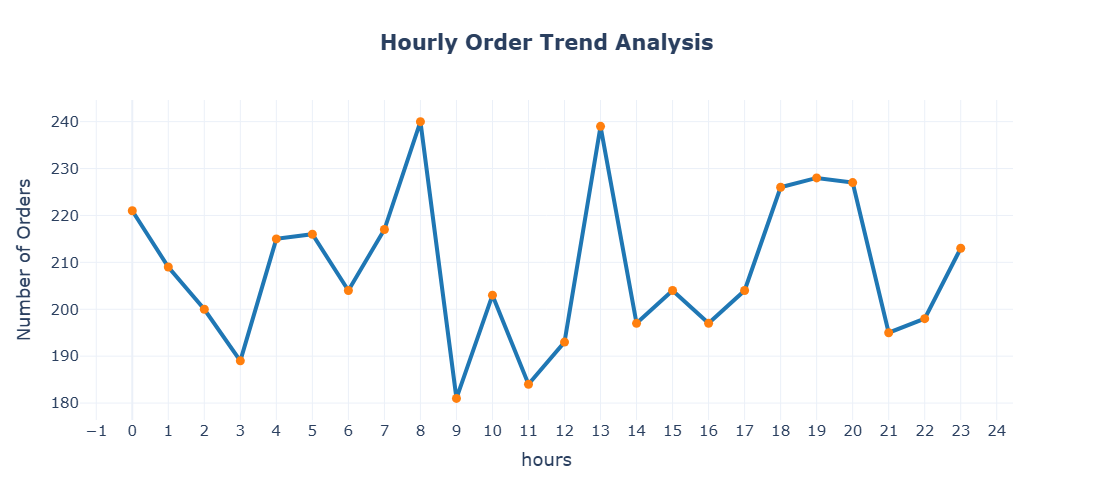

In [23]:
import plotly.express as px

# Group data by hour
hourly_orders = (
    df.groupby("hours")["order_id"]
      .count()
      .reset_index(name="Orders")
)

# Create Interactive Line Chart
fig = px.line(
    hourly_orders,
    x="hours",
    y="Orders",
    markers=True,
    title="<b>Hourly Order Trend Analysis</b>",
    labels={
        "hour": "Hour of the Day",
        "Orders": "Number of Orders"
    },
    template="plotly_white"
)

# Customize the chart
fig.update_traces(
    line=dict(color="#1f77b4", width=4),
    marker=dict(size=9, color="#ff7f0e")
)

fig.update_layout(
    title_x=0.5,
    font=dict(size=15),
    xaxis=dict(
        tickmode='linear',
        dtick=1,
        showgrid=True
    ),
    yaxis=dict(showgrid=True),
    hovermode="x unified",
    width=900,
    height=500
)

fig.show()

**Graph Explanation**
* The line chart shows how the number of orders changes throughout the day.
* Order volume reaches its highest level around 8 AM and 1 PM, indicating peak customer activity.
* A noticeable drop in orders occurs around 9 AM, representing a low-demand period.
* These insights help Blinkit optimize staffing, inventory management, and delivery operations during peak and off-peak hours.

**Monthly Orders Analysis**

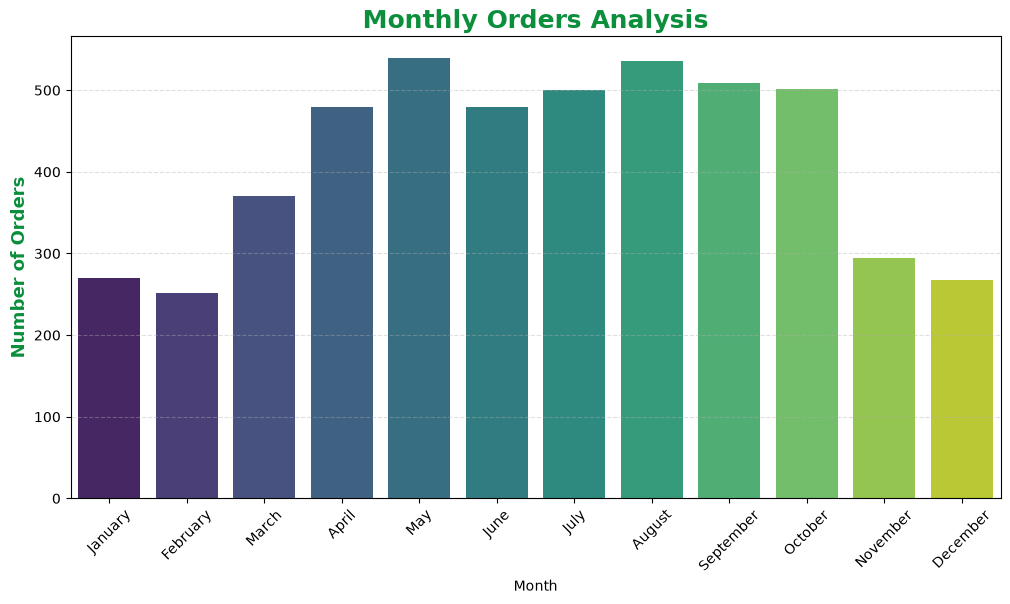

In [52]:
month_order = [
    "January", "February", "March", "April",
    "May", "June", "July", "August",
    "September", "October", "November", "December"
]
monthly_orders = (
    df.groupby("month name")["order_id"]
      .count()
      .reindex(month_order)
      .reset_index(name="Orders")
)

plt.figure(figsize=(12,6))

sns.barplot(
    data=monthly_orders,
    x="month name",
    y="Orders",
   hue="month name", palette="viridis"
)

plt.title("Monthly Orders Analysis", fontsize=18, fontweight="bold",color="#0B8F3C")
plt.xlabel("Month")
plt.ylabel("Number of Orders",fontsize=13, fontweight="bold", color="#0B8F3C")

plt.xticks(rotation=45)
plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.show()

**Graph Explanation**
* The chart shows the total number of orders placed in each month.
* Orders increase during the middle months and decrease in some later months.
* This analysis helps identify seasonal demand patterns for better inventory and staffing planning.

**Payment Method Distribution**

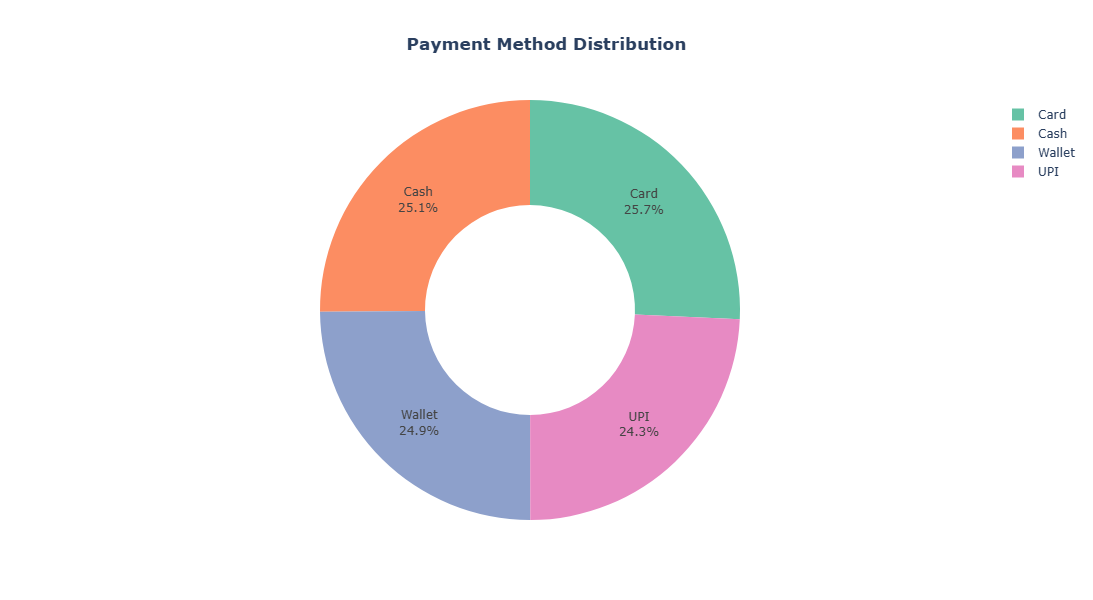

In [25]:


payment = (
    df["payment_method"]
    .value_counts()
    .reset_index()
)

payment.columns = ["Payment Method", "Orders"]

fig = px.pie(
    payment,
    names="Payment Method",
    values="Orders",
    hole=0.5,
    color="Payment Method",
    color_discrete_sequence=px.colors.qualitative.Set2,
    title="<b>Payment Method Distribution</b>"
)

fig.update_traces(
    textinfo="percent+label",
    textposition="inside"
)

fig.update_layout(
    title_x=0.5,
    width=700,
    height=600
)

fig.show()

**Graph Explanation**
* The donut chart displays the percentage share of each payment method.
* It clearly shows which payment method is most popular among customers.
* Businesses can use this information to optimize payment options and encourage the use of preferred payment methods

**Delivery Status Distribution**

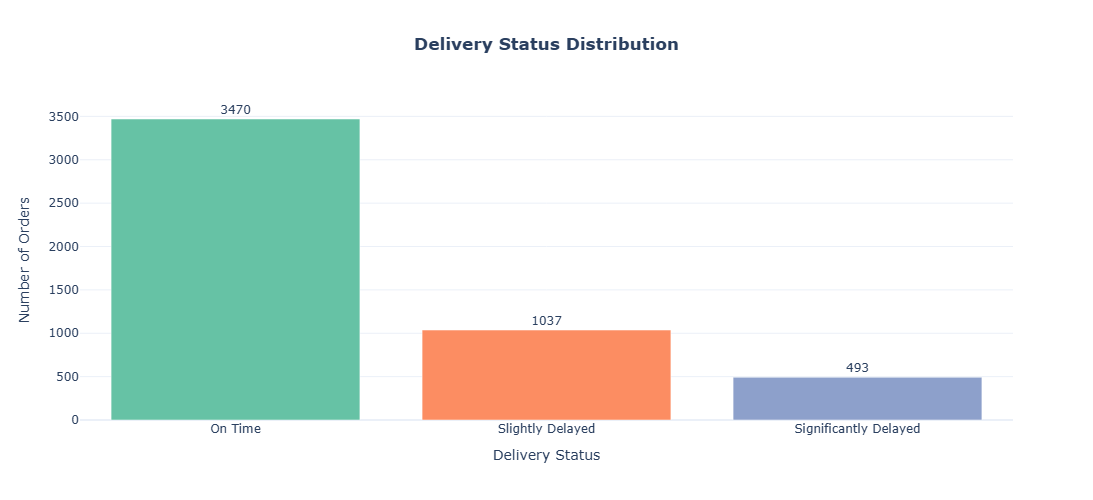

In [26]:
import plotly.express as px

delivery_status = (
    df["delivery_status"]
    .value_counts()
    .reset_index()
)

delivery_status.columns = ["Delivery Status", "Orders"]

fig = px.bar(
    delivery_status,
    x="Delivery Status",
    y="Orders",
    text="Orders",
    color="Delivery Status",
    color_discrete_sequence=px.colors.qualitative.Set2,
    title="<b>Delivery Status Distribution</b>",
    template="plotly_white"
)

fig.update_traces(
    textposition="outside"
)

fig.update_layout(
    title_x=0.5,
    xaxis_title="Delivery Status",
    yaxis_title="Number of Orders",
    width=800,
    height=500,
    showlegend=False
)

fig.show()

**Graph Explanation**
* The chart shows the number of orders for each delivery status.
* The status with the tallest bar represents the most common delivery outcome.
* This analysis helps monitor delivery performance and identify areas that may require operational improvements.

### Total order amount by payment method

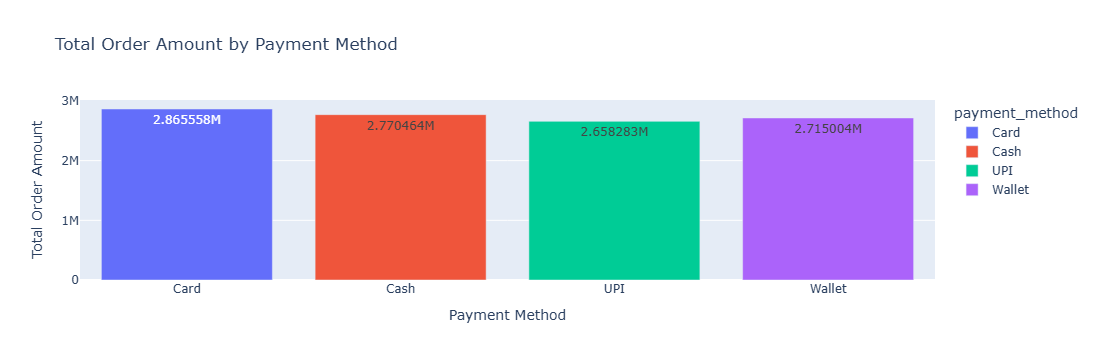

In [27]:
import plotly.express as px

payment_sales = df.groupby("payment_method")["order_total"].sum().reset_index()

fig = px.bar(
    payment_sales,
    x="payment_method",
    y="order_total",
    color="payment_method",
    title="Total Order Amount by Payment Method",
    text_auto=True
)

fig.update_layout(
    xaxis_title="Payment Method",
    yaxis_title="Total Order Amount"
)

fig.show()

**Explanation**

* The graph compares the total order amount generated by each payment method.
* It helps identify which payment method customers use the most for making purchases.
* The payment method with the highest bar/slice contributes the highest total revenue.
* The payment method with the lowest bar/slice contributes the least revenue.
* The graph provides a clear comparison of customer payment preferences.

### Total orders by Weekady

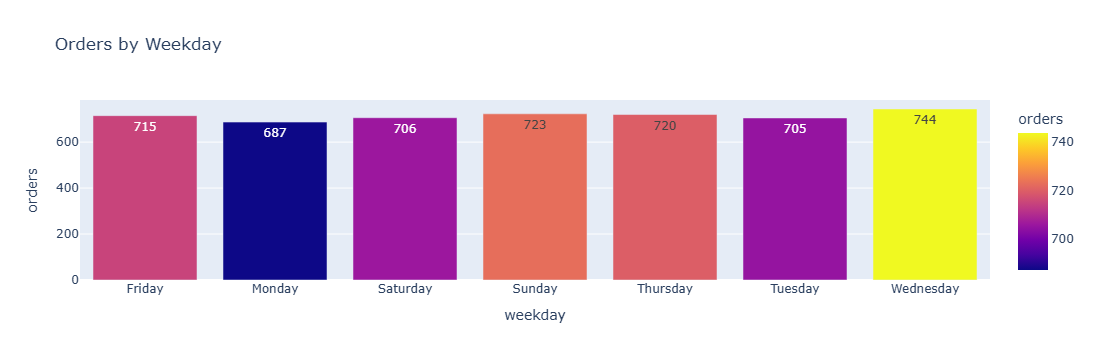

In [35]:
weekday = df.groupby("weekday").size().reset_index(name="orders")

fig = px.bar(
    weekday,
    x="weekday",
    y="orders",
    color="orders",
    text="orders",
    title="Orders by Weekday"
)

fig.show()

**Explanation**

* Wednesday has the highest number of orders (744), making it the busiest day of the week.
* Tuesday recorded 730 orders, which is also higher than most other weekdays.
* Sunday received 723 orders, showing strong customer demand even on weekends.
* Thursday had 720 orders, indicating a consistent level of activity.
* Friday recorded 715 orders, only slightly lower than Thursday.
* Saturday had 706 orders, showing a small decline compared to the middle of the week.
* Monday has the lowest number of orders (687), making it the least busy day.


## Payment Method By Weekday

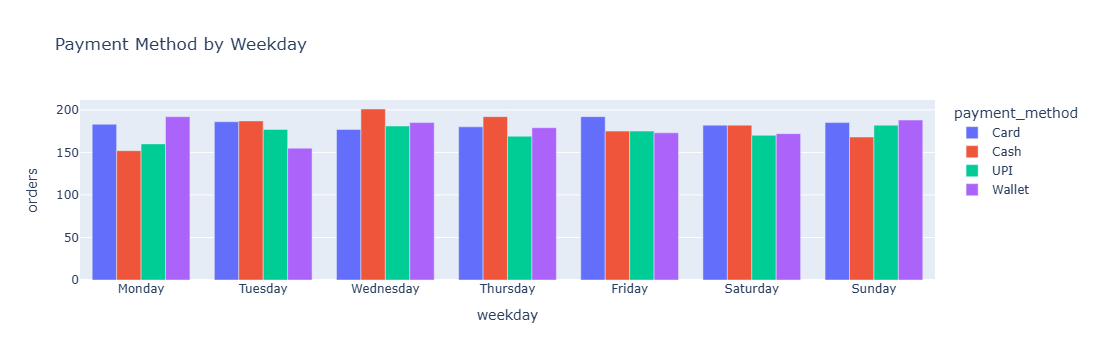

In [40]:
order = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]

payment_weekday = df.groupby(["weekday","payment_method"]).size().reset_index(name="orders")

payment_weekday["weekday"] = pd.Categorical(
    payment_weekday["weekday"],
    categories=order,
    ordered=True
)

payment_weekday = payment_weekday.sort_values("weekday")

fig = px.bar(
    payment_weekday,
    x="weekday",
    y="orders",
    color="payment_method",
    barmode="group",
    title="Payment Method by Weekday"
)

fig.show()

**Explanation**
* Monday shows a balanced distribution of all payment methods, with Wallet being slightly more popular.
* Tuesday has almost equal usage of Card and Cash, while Wallet is used the least.
* Wednesday records the highest Cash payments, indicating many customers prefer cash on this day.
* Thursday also shows Cash as the most preferred payment method.
* Friday has a fairly even distribution across all payment methods.
* Saturday shows similar usage of Card and Cash, with slightly fewer UPI and Wallet payments.
* Sunday has higher usage of Wallet and Card compared to Cash.

### Orders by Month and Payment Method

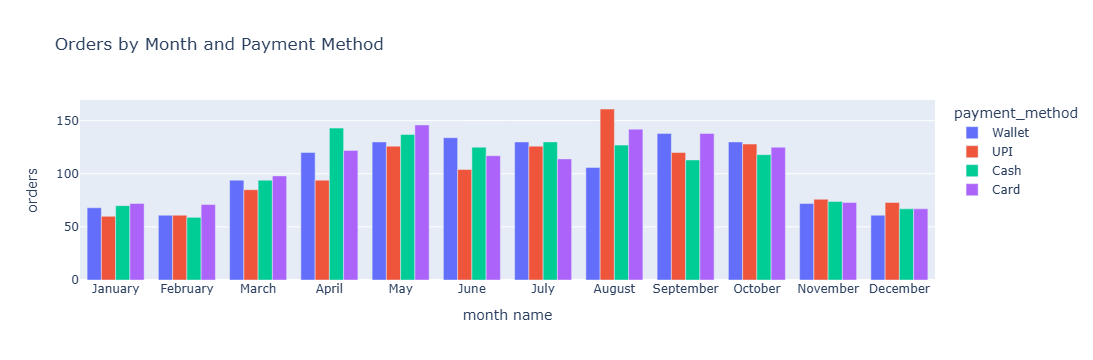

In [55]:
month_order = [
    "January", "February", "March", "April", "May", "June",
    "July", "August", "September", "October", "November", "December"
]

month_payment = df.groupby(["month name", "payment_method"]).size().reset_index(name="orders")

month_payment["month name"] = pd.Categorical(
    month_payment["month name"],
    categories=month_order,
    ordered=True
)

month_payment = month_payment.sort_values("month name")

fig = px.bar(
    month_payment,
    x="month name",
    y="orders",
    color="payment_method",
    barmode="group",
    title="Orders by Month and Payment Method"
)

fig.show()

**Explanation**
* January and February have the lowest number of orders across all payment methods.
* Order volume starts increasing from March and continues to grow until May–June.
* August records the highest number of UPI payments, making it the peak month for UPI transactions.
* Cash payments are highest in April and May, indicating strong customer preference during these months.
* Wallet and Card payments remain relatively stable throughout the year with only small fluctuations.
* Order activity begins to decline after October, with November and December showing lower order volumes.


**Research Questions**

**Research Question 1**
* Q1. What is the total revenue generated from all Blinkit orders?

In [60]:
total_revenue = df["order_total"].sum()
print("Total Revenue:", total_revenue)

Total Revenue: 11009308.5


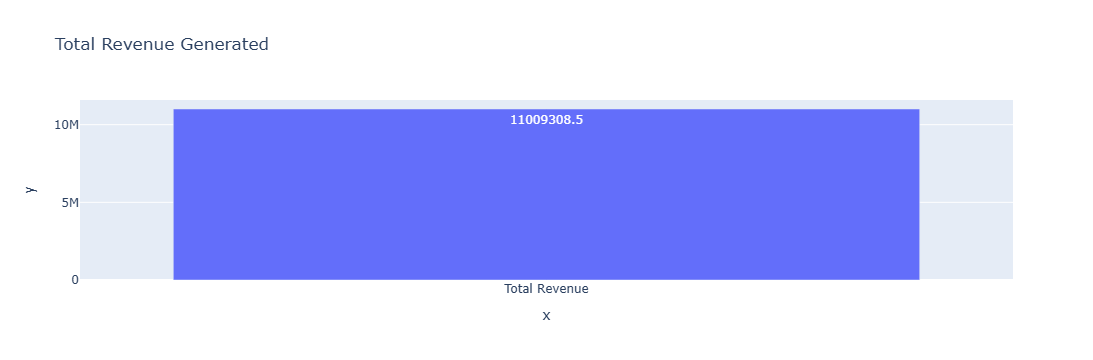

In [61]:
fig = px.bar(
x=["Total Revenue"],
    y=[total_revenue],
    text=[total_revenue],
    title="Total Revenue Generated"
)

fig.show()

**Analysis**
* The graph displays the total revenue generated from all customer orders.
* It represents the overall sales performance of the business.
* Higher revenue indicates stronger customer demand and order value.
    
**Key Insights**
* Total revenue reflects the overall business performance.
* It can be used as a benchmark for future sales comparisons.
* Revenue analysis helps evaluate business growth over time.
* Higher revenue indicates healthy customer engagement.

**Research Question 2**
* Which payment method is used most frequently by customers?

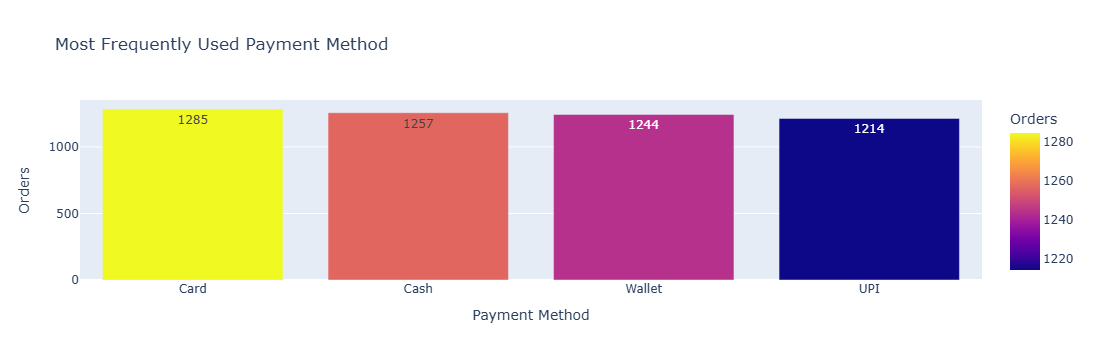

In [62]:
payment_orders = df["payment_method"].value_counts().reset_index()
payment_orders.columns = ["Payment Method", "Orders"]

fig = px.bar(
    payment_orders,
    x="Payment Method",
    y="Orders",
    color="Orders",
    text="Orders",
    title="Most Frequently Used Payment Method"
)

fig.show()

**Analysis**
* The graph compares the total number of orders placed using each payment method.
* Card is the most preferred payment method with 1,285 orders.
* Cash (1,257) and Wallet (1,244) follow closely behind.
* UPI has the lowest number of orders (1,214), although the difference is small.
*Customer payment preferences are well distributed across all payment methods.

**Key Insights**
* Card is the most frequently used payment method.
* UPI is the least used payment method in the dataset.
* The difference between the highest and lowest payment methods is relatively small, indicating balanced customer preferences.
* Supporting multiple payment options is important because customers actively use all available methods.
* Businesses can encourage greater UPI adoption through cashback or discount offers.

**Research Question 3**
* On which weekday are the maximum orders placed?

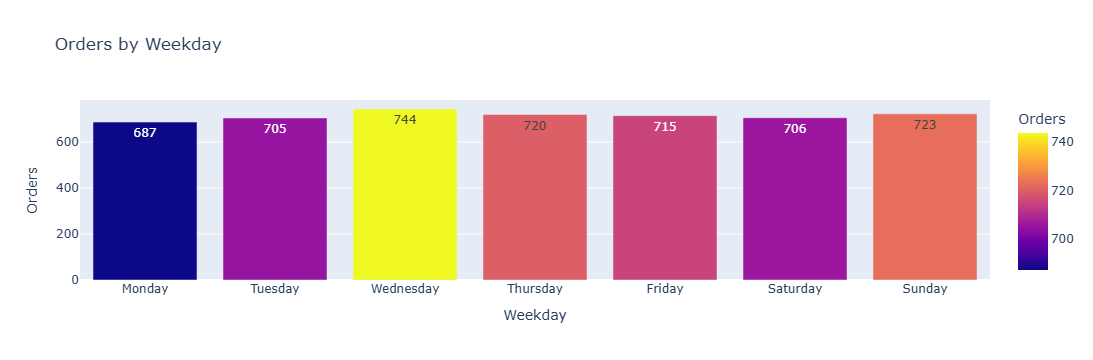

In [65]:
weekday = (
    df["weekday"]
    .value_counts()
    .reindex(["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"])
    .reset_index()
)

weekday.columns = ["Weekday", "Orders"]

fig = px.bar(
    weekday,
    x="Weekday",
    y="Orders",
    color="Orders",
    text="Orders",
    title="Orders by Weekday"
)

fig.show()

**Analysis**
* The graph compares the total number of orders placed on each weekday.
* Wednesday records the highest number of orders (744).
* Monday has the lowest order count (687).
* Order volume remains fairly consistent throughout the week.
* Mid-week days experience slightly higher customer activity than weekends.

**Key Insights**
* Wednesday is the busiest day for customer orders.
* Monday records the lowest customer activity.
* Customer demand remains stable throughout the week.
* Businesses should schedule more delivery staff during Tuesday to Thursday.
* Weekly order trends can support workforce and inventory planning.

**Research Question 4**
* During which hour of the day are the highest number of orders received?

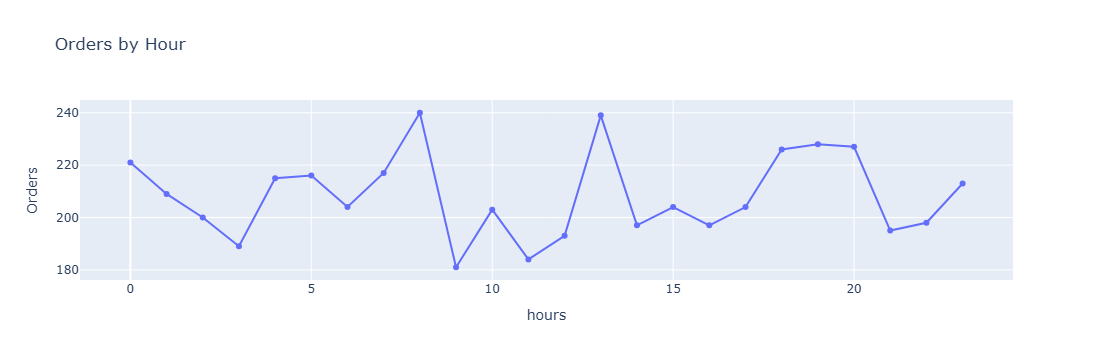

In [67]:
hour_orders = df.groupby("hours").size().reset_index(name="Orders")

fig = px.line(
    hour_orders,
    x="hours",
    y="Orders",
    markers=True,
    title="Orders by Hour"
)

fig.show()

**Analysis**
* The graph shows how order volume changes throughout the day.
* Customer orders fluctuate across different hours.
* The highest order activity occurs around 8 AM and 1 PM, where orders reach approximately 240.
* Order volume decreases during some morning and late-evening hours before increasing again.

**Key Insights**
* Peak customer demand occurs around 8 AM and 1 PM.
* Some morning and evening hours receive fewer orders.
* Businesses should allocate more delivery resources during peak hours.
* Hourly order trends help improve delivery efficiency.
* Peak-hour promotions can further increase customer engagement.

**Research Question 5**
* Which month records the highest number of orders?

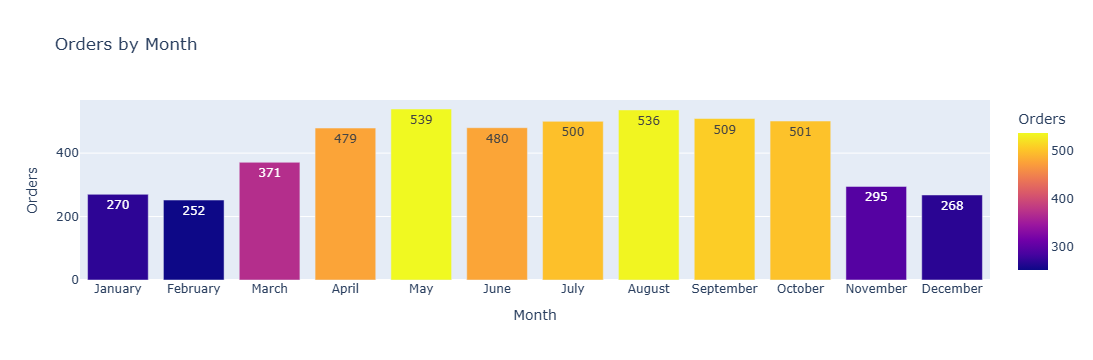

In [68]:
month_order = [
    "January","February","March","April","May","June",
    "July","August","September","October","November","December"
]

month_orders = df["month name"].value_counts().reindex(month_order).reset_index()
month_orders.columns = ["Month", "Orders"]

fig = px.bar(
    month_orders,
    x="Month",
    y="Orders",
    color="Orders",
    text="Orders",
    title="Orders by Month"
)

fig.show()

**Analysis**
* The graph compares the total number of orders across all months.
* Orders increase steadily from January and reach their highest level in May (539 orders).
* August (536 orders) also records very high customer activity.
* After October, the number of orders declines significantly.
* February (252 orders) records the lowest monthly order count.
    
**Key Insights**
* May is the highest-performing month with 539 orders.
* August is the second-highest month with 536 orders.
* February records the lowest number of customer orders.
* Customer demand is strongest between April and October.
* Businesses can increase marketing efforts during low-demand months to improve sales.

**Research Question 6**
* What is the distribution of different delivery statuses?

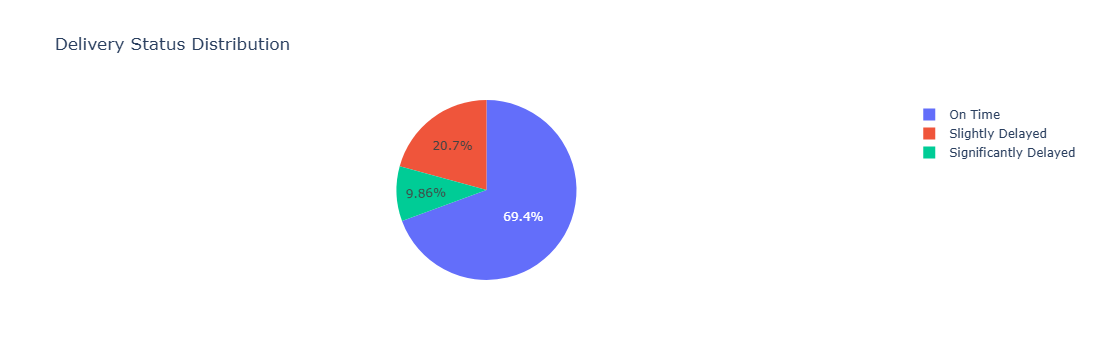

In [69]:
delivery_status = df["delivery_status"].value_counts().reset_index()
delivery_status.columns = ["Delivery Status", "Orders"]

fig = px.pie(
    delivery_status,
    names="Delivery Status",
    values="Orders",
    title="Delivery Status Distribution"
)

fig.show()

**Analysis**
* The pie chart shows the percentage distribution of delivery statuses.
* On Time deliveries account for 69.4% of all orders.
* Slightly Delayed deliveries represent 20.7%.
* Significantly Delayed deliveries account for only 9.9%.
* Most customer orders are delivered successfully and on schedule.

**Key Insights**
* Nearly 70% of orders are delivered on time, indicating strong delivery performance.
* Around 21% of orders experience slight delays.
* Only 10% of orders are significantly delayed, showing relatively good operational efficiency.
* Reducing delayed deliveries can further improve customer satisfaction.
* Continuous monitoring of delivery performance will help maintain service quality and customer trust.

**Conclusion**

* This project successfully analyzed the Blinkit Orders Dataset to understand customer ordering behavior, payment preferences, revenue trends, and 
delivery performance. After cleaning and preprocessing the data, various visualizations were created to identify meaningful patterns and answer the 
research questions.
The analysis showed that customer orders vary across different hours, weekdays, and months, helping identify peak demand periods. Payment
method analysis highlighted customer preferences and the revenue contribution of each payment option. Delivery status analysis provided insights 
into order fulfillment performance and
operational efficiency.
Overall, the project demonstrates how Python, Pandas, Plotly, and Jupyter Notebook can be used to transform raw order data into meaningful business
insights. These findings can help businesses optimize staffing, improve delivery operations, enhance the customer experience, and support data-driven 
decision-making for future growth.